# One day of a drift mouse, in figures

Annotated example figures for **ROS-2328, 2026-07-28** (day 1 of 11): a natural-image recording and a grating
recording of the same imaging site, linked cell by cell by CellReg. Every value comes from the database. Every
measure is named as it appears in its table, and its definition is in the caption.

| figure | shows | tables |
|---|---|---|
| 1 | the recording: imaging field, eye camera with the pupil rim fit and glint, FaceMap | `imaging.MotionCorrection.Summary`, `pupil_tracking.PupilEllipseFitting` (set 12), `CorrectedGlint` (set 3), `facemap.FacialSignal` |
| 2 | 90 s of everything: stimuli, running, pupil, gaze, face motion, three cells (dF/F0, CASCADE, OASIS) | `imaging.Dff0`, `imaging.Activity`, `behavior`, the above |
| 3 | how a response is measured: the read-out windows | `responsiveness.ReadoutParamSet`, `EventSet`, `ScreenTiming` |
| 4 | natural-image responses: repeats, reliability, ZETA | `responsiveness.Readout`, `Zeta` |
| 5 | grating responses and orientation / direction tuning, with the levels of tuning | `responsiveness.Readout.Condition`, `DirectionTuning` |
| 6 | quality measures of every cell, with the thresholds | `responsiveness.ScanQuality`, `Quality`, `TraceQuality`, `CellRule`, `imaging.RoiQC` |
| 7 | responses, running and pupil | the export of notebook 23 |

**Example cells** are chosen by quality, not by eye: present in both recordings (CellReg run `ImagesAndGratings`),
not rejected by ROI QC, significantly tuned to gratings with a good fit, reliable to gratings and to natural images.
The style follows Nature's figure guide: 7-pt sans-serif text, 0.5-pt axes, panel letters a, b, c, widths of 89 mm
(one column) or 183 mm (two columns).

In [1]:
import os, json, logging, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle
from matplotlib.lines import Line2D

# the export notebook's functions: connection, trials, behaviour, pupil, camera clock (its "# DEF" cells)
for _c in json.load(open("23_drift_export_from_datajoint.ipynb"))["cells"]:
    _s = "".join(_c["source"])
    if _c["cell_type"] == "code" and _s.startswith("# DEF"):
        exec(_s)
resp = schema("responsiveness")

MM = 1 / 25.4
W1, W2 = 89 * MM, 183 * MM
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "legend.frameon": False, "axes.linewidth": 0.5, "xtick.major.width": 0.5,
    "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2, "lines.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 220, "savefig.dpi": 600,
    "pdf.fonttype": 42, "axes.titleweight": "normal", "axes.titlepad": 3})
# Okabe-Ito colours (colour-blind safe)
COL = dict(dff="#000000", cascade="#D55E00", oasis="#0072B2", run="#009E73", pupil="#CC79A7", gaze="#56B4E9",
           face="#E69F00", stim="#BBBBBB", test="#F0E442", grey="#888888")
CELL_COL = ["#0072B2", "#D55E00", "#009E73"]

def panel(ax, letter, x=-0.16, y=1.06):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left")

def scalebar(ax, x, y, dx=None, dy=None, lx="", ly="", lw=0.8):
    if dx: ax.plot([x, x + dx], [y, y], color="k", lw=lw, clip_on=False); ax.text(x + dx / 2, y, lx, ha="center", va="top", fontsize=6)
    if dy: ax.plot([x, x], [y, y + dy], color="k", lw=lw, clip_on=False); ax.text(x, y + dy / 2, ly + " ", ha="right", va="center", fontsize=6)

def clean(ax):
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])

FIGDIR = os.path.expanduser(os.environ.get("DRIFT_FIG_DIR", "~/drift_example_figures")); os.makedirs(FIGDIR, exist_ok=True)
def save(fig, name):
    fig.savefig(f"{FIGDIR}/{name}.pdf", bbox_inches="tight"); fig.savefig(f"{FIGDIR}/{name}.png", bbox_inches="tight", dpi=300)

datajoint 0.14.8 | read-only session: yes


## The day and the example cells

Two recordings of ROS-2328's site on 2026-07-28: natural images (`scan9G1EWD9V`) and drifting gratings
(`scan9G1EUK4K`). The CellReg run `…_ImagesAndGratings_CR` registered both, so a `cell_index` names the same neuron
in both. For each neuron the cell below collects, from `roselab_responsiveness`:

* gratings, read-out 16, CASCADE: `resp_p` (t-test response vs baseline), `oracle_r` (reliability across repeats),
  and from `DirectionTuning` (`tuning_idx` 1): `hotelling_p`, `gosi`, `gdsi`, `fit_r2_cv`, `fit_chi2_p`, `fit_at_bound`;
* natural images, read-out 11, CASCADE: `zeta_p` (ZETA test), `oracle_r`, `fev`;
* `snr_s2p` of the dF/F0 and CASCADE traces (`TraceQuality`).

Quality bar (the lab's rules): `hotelling_p` < 0.05, `fit_r2_cv` > 0.5, `fit_chi2_p` > 0.05, `resp_p` < 0.05, grating
`oracle_r` ≥ 0.18, `zeta_p` < 0.001, image `oracle_r` ≥ 0.08, no ROI-QC rejection, fit not at a parameter bound,
and dF/F0 `snr_s2p` in the top quarter of the recording, so that every trace shown is clean.
From the cells that pass, three examples: the most **orientation**-selective (high `gosi`, low `gdsi`), the most
**direction**-selective (highest `gdsi`), and the most reliable natural-image responder.

In [2]:
MOUSE = "ROS-2328"
NI = {"session_id": "sess9G1EWD9V", "scan_id": "scan9G1EWD9V"}
GR = {"session_id": "sess9G1EUK4K", "scan_id": "scan9G1EUK4K"}
cur_n, cur_g = latest_curation(NI), latest_curation(GR)
run_ig = (cellreg.CellRegRun & {"subject": MOUSE} & 'result_file LIKE "%ImagesAndGratings_CR%"').fetch1("cellreg_run_id")
def members(cur, name):
    return pd.DataFrame((cellreg.CellRegResult.Member & {"cellreg_run_id": run_ig} & cur).fetch("cell_index", "mask", as_dict=True)).rename(columns={"mask": name})
pairs = members(cur_g, "mask_g").merge(members(cur_n, "mask_n"), on="cell_index")

GK = {"trace_source": "cascade25", "event_selector": "gratings", "readout_idx": 16}
NK = {"trace_source": "cascade25", "event_selector": "nat_images_repeated", "readout_idx": 11}
def frame(q, attrs, name, rename=None):
    return pd.DataFrame(q.fetch("mask", *attrs, as_dict=True)).rename(columns={"mask": name, **(rename or {})})
tun = frame(resp.DirectionTuning.Cell & cur_g & GK & {"tuning_idx": 1},
            ["gosi", "gdsi", "osi", "dsi", "oi", "di", "pref_ori", "pref_dir", "hotelling_p", "fit_r2_cv", "fit_chi2_p", "fit_at_bound", "gosi_cv", "gdsi_cv"], "mask_g")
rog = frame(resp.Readout.Cell & cur_g & GK, ["resp_p", "oracle_r"], "mask_g", {"oracle_r": "oracle_g"})
zn = frame(resp.Zeta.Cell & cur_n & NK & {"zeta_idx": 1}, ["zeta_p"], "mask_n")
ron = frame(resp.Readout.Cell & cur_n & NK, ["oracle_r", "fev"], "mask_n", {"oracle_r": "oracle_n"})
tq = frame(resp.TraceQuality.Cell & cur_n & {"trace_source": "cascade25"}, ["snr_s2p"], "mask_n")
tqd = frame(resp.TraceQuality.Cell & cur_n & {"trace_source": "dff0_r2"}, ["snr_s2p"], "mask_n", {"snr_s2p": "snr_dff"})
rej_n = set((dj.U("mask") & (imaging.RoiQC.Rejected & cur_n)).fetch("mask")); rej_g = set((dj.U("mask") & (imaging.RoiQC.Rejected & cur_g)).fetch("mask"))
soma_n = set(soma_query(cur_n).fetch("mask")); soma_g = set(soma_query(cur_g).fetch("mask"))
cand = pairs.merge(tun, on="mask_g").merge(rog, on="mask_g").merge(zn, on="mask_n").merge(ron, on="mask_n").merge(tq, on="mask_n").merge(tqd, on="mask_n")
SNR_DFF_MIN = float(tqd.snr_dff.quantile(0.75))          # top quarter of dF/F0 SNR: clean traces
cand = cand[cand.mask_n.isin(soma_n) & cand.mask_g.isin(soma_g) & ~cand.mask_n.isin(rej_n) & ~cand.mask_g.isin(rej_g)]
good = cand[(cand.hotelling_p < 0.05) & (cand.fit_r2_cv > 0.5) & (cand.fit_chi2_p > 0.05) & (cand.fit_at_bound == 0)
            & (cand.resp_p < 0.05) & (cand.oracle_g >= 0.18) & (cand.zeta_p < 0.001) & (cand.oracle_n >= 0.08)
            & (cand.snr_dff >= SNR_DFF_MIN)]
ori_cell = good[good.gdsi < 0.2].sort_values("gosi").iloc[-1]
dir_cell = good.drop(ori_cell.name).sort_values("gdsi").iloc[-1]
ni_cell = good.drop([ori_cell.name, dir_cell.name]).sort_values("oracle_n").iloc[-1]
EX = pd.DataFrame([ori_cell, dir_cell, ni_cell], index=["orientation-selective", "direction-selective", "image-reliable"])
print(f"{len(pairs)} neurons in both recordings, {len(good)} pass the quality bar (dF/F0 snr_s2p >= {SNR_DFF_MIN:.2f})")
EX[["cell_index", "mask_n", "mask_g", "gosi", "gdsi", "pref_ori", "hotelling_p", "fit_r2_cv", "oracle_g", "zeta_p", "oracle_n", "snr_s2p", "snr_dff"]].round(3)

768 neurons in both recordings, 16 pass the quality bar (dF/F0 snr_s2p >= 0.63)


,cell_index,mask_n,mask_g,gosi,gdsi,pref_ori,hotelling_p,fit_r2_cv,oracle_g,zeta_p,oracle_n,snr_s2p,snr_dff
orientation-selective,204.0,204.0,100.0,0.736,0.116,83.992,0.001,0.513,0.685,0.000,0.432,0.896,0.688
direction-selective,2.0,2.0,32.0,0.700,0.607,129.485,0.001,0.548,0.740,0.001,0.107,0.921,0.862
image-reliable,545.0,546.0,436.0,0.528,0.287,73.535,0.000,0.908,0.759,0.000,0.725,0.844,0.798


In [3]:
# data of the day: frame clocks, trials, traces of the example cells, behaviour (natural-image recording)
ft_n, ft_g = frame_times_2p(NI), frame_times_2p(GR)
tr_n = image_trials(NI, ft_n); n_win = int(tr_n.off_frame[0] - tr_n.on_frame[0] + 2)
def traces(cur, mask):
    k = dict(cur, mask=int(mask))
    dff = (imaging.Dff0.Trace & k & {"dff_paramset_idx": 2}).fetch("dff")[0]
    cas = (imaging.Activity.Trace & k & {"extraction_method": "cascade_inference_25ms_filter"}).fetch("activity_trace")[0]
    oas = (imaging.Activity.Trace & k & {"extraction_method": "suite2p_deconvolution"}).fetch("activity_trace")[0]
    return {"dff": np.asarray(dff, float), "cascade": np.asarray(cas, float), "oasis": np.asarray(oas, float)}
TN = {i: traces(cur_n, EX.loc[i, "mask_n"]) for i in EX.index}
TG = {i: traces(cur_g, EX.loc[i, "mask_g"]) for i in EX.index}
run_n = running_speed(NI, ft_n)
seg_n = face_segment(NI); row_t, video_t, cam_n = camera_times(seg_n); fm_n = face_frames(seg_n)
pf_n, pinfo_n = pupil_frames(NI)
nv = min(len(pf_n["size"]), len(video_t)); vt = video_t[:nv]
P2 = {k: to_2p(pf_n[k][:nv], vt, ft_n) for k in ("size", "gaze_x", "gaze_y", "azimuth", "elevation", "interpolated")}
E2 = to_2p(fm_n["energy"], row_t, ft_n); M2 = to_2p(fm_n["mot"][:, :3], row_t, ft_n)
print("camera clock:", cam_n["sync_method"], "| pupil:", pinfo_n["pupil_code_version"], "| frac accepted", pinfo_n["frac_pupil_accepted"])

camera clock: camera_frames | pupil: image_rim_v4.1 (v4 + anchored fallback centre, 2026-11-24) | frac accepted 0.990657


## Figure 1 · The recording

**a**, Mean two-photon image of the site (`MotionCorrection.Summary.average_image`); the three example neurons
outlined in their colours (ROI pixels, `Segmentation.Mask`). **b**, One face-camera frame (60 Hz) around the eye with
the set-12 pupil fit: the ellipse fitted to the pupil rim in the image (blue) and its centre (`X0+ir`, `Y0+ir`), and the
corneal reflection of the IR light (glint, set 3, yellow). The pupil − glint vector (arrow) is the gaze signal exported
as `pupil_center`. **c**, A frame rejected by set 12's outlier rejection (`accepted` = False; here the rim was found
on too few rays, typically a blink or eyelid): its fit is drawn dashed, and the frame is never used. **d**, FaceMap
(`FacialSignal`): the mean face frame and the spatial masks of the first three motion-SVD components (red / blue =
opposite signs); their time courses are behaviour columns 13–15. **e**, Pupil diameter (`diameter` = ellipse long
axis, px) in the minute with the most rejected frames: set-12 values of accepted frames (black), rejected frames
(ticks), and the exported trace, in which rejected frames are interpolated (pink).

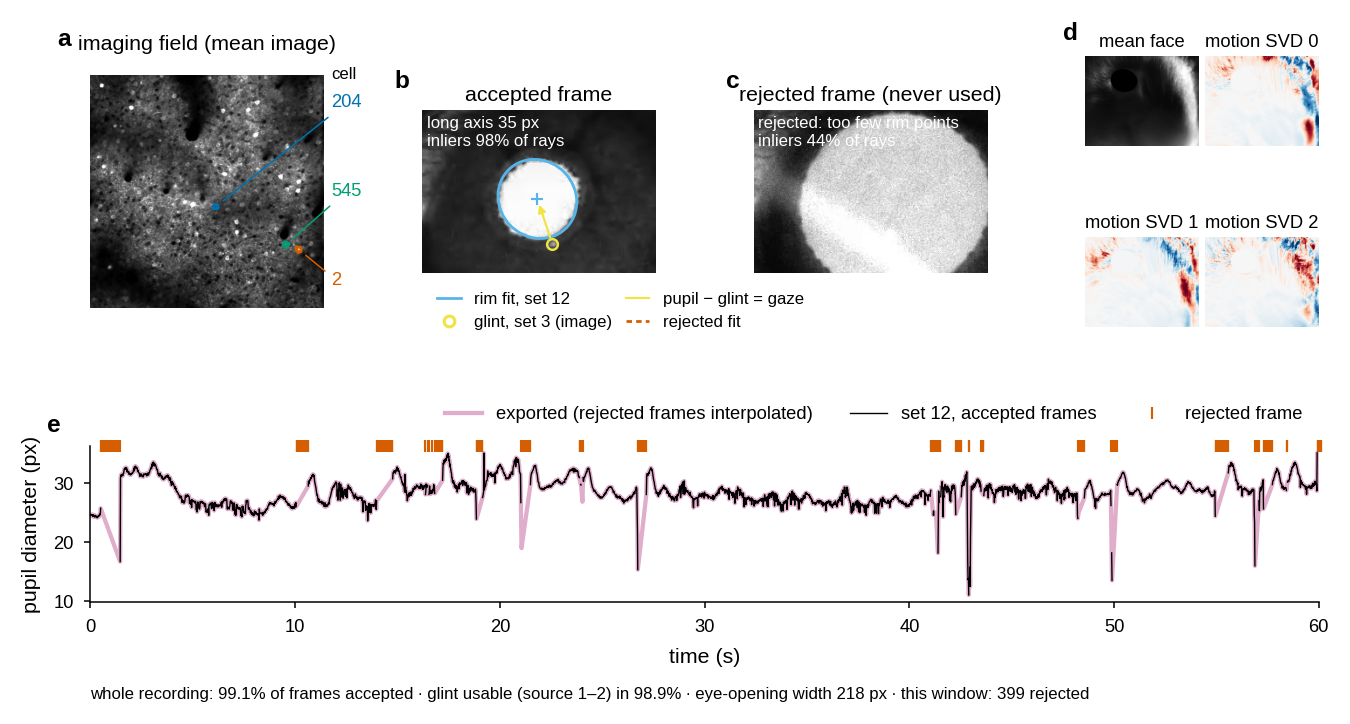

In [4]:
import cv2
fig = plt.figure(figsize=(W2, 0.52 * W2))
fig.set_size_inches(W2, 0.47 * W2)
gs = fig.add_gridspec(2, 4, height_ratios=[1, 0.48], hspace=0.38, wspace=0.42, width_ratios=[1.0, 1, 1, 1])

# a: imaging field with the example ROIs, labels on leader lines
ax = fig.add_subplot(gs[0, 0]); panel(ax, "a", x=-0.14, y=1.1)
avg = (imaging.MotionCorrection.Summary & cur_n).fetch("average_image")[0]
lo, hi = np.percentile(avg, [1, 99.7]); ax.imshow(avg, cmap="gray", vmin=lo, vmax=hi); clean(ax)
cents = []
for c, (name, row) in zip(CELL_COL, EX.iterrows()):
    xp, yp = (imaging.Segmentation.Mask & dict(cur_n, mask=int(row.mask_n))).fetch1("mask_xpix", "mask_ypix")
    img = np.zeros(avg.shape, bool); img[yp, xp] = True
    ax.contour(img, levels=[0.5], colors=[c], linewidths=0.9); cents.append((yp.mean(), xp.mean(), c, int(row.cell_index)))
ylab = np.linspace(0.12, 0.88, len(cents)) * avg.shape[0]
for yl, (cy, cx, c, ci) in zip(ylab, sorted(cents)):
    ax.annotate(f"{ci}", xy=(cx, cy), xytext=(avg.shape[1] * 1.03, yl), color=c, fontsize=6, va="center",
                annotation_clip=False, arrowprops=dict(arrowstyle="-", color=c, lw=0.5, shrinkA=0, shrinkB=3))
ax.set_title("imaging field (mean image)", pad=8); ax.text(1.03, 0.97, "cell", transform=ax.transAxes, fontsize=5.5, ha="left", va="bottom")

# b, c: eye frames with the set-12 fit and the set-3 glint
pk = (pupil.PupilEllipseFitting & NI & {"parameter_id": PUPIL_SET, "model_name": EYE_MODEL} & 'recording_id LIKE "%face%"').fetch1("KEY")
ell = (pupil.PupilEllipseFitting & pk).fetch1("ellipse_dict")
gk = {k: v for k, v in pk.items() if k != "parameter_id"}
gx, gy, gs_src = (pupil.CorrectedGlint & gk & {"glint_param_id": GLINT_SET}).fetch1("glint_x", "glint_y", "glint_source")
video = (pupil.PupilEllipseFitting.ImageFit & pk).fetch1("video_file")
acc = np.array([bool(e and e["accepted"]) for e in ell])
has_fit = np.array([bool(e) and np.isfinite(e.get("X0+ir", np.nan)) and np.isfinite(e.get("a", np.nan)) for e in ell])
cxm = np.nanmedian([e["X0+ir"] for e in ell[::300] if e and e["accepted"]]); cym = np.nanmedian([e["Y0+ir"] for e in ell[::300] if e and e["accepted"]])
RIM, GLI = "#56B4E9", "#F0E442"
def eye_frame(ax, i, title):
    cap = cv2.VideoCapture(video); cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read(); cap.release()
    x0, y0 = int(cxm) - 100, int(cym) - 70
    ax.imshow(fr[y0:y0 + 140, x0:x0 + 200, 0], cmap="gray", extent=(x0, x0 + 200, y0 + 140, y0), vmin=0, vmax=255)
    e = ell[i]
    if has_fit[i]:
        ax.add_patch(Ellipse((e["X0+ir"], e["Y0+ir"]), 2 * e["a"], 2 * e["b"], angle=np.degrees(e["angle_to_x"]), fill=False,
                             ec=RIM if e["accepted"] else "#D55E00", lw=0.9, ls="-" if e["accepted"] else (0, (2, 1.5))))
        ax.plot(e["X0+ir"], e["Y0+ir"], "+", color=RIM if e["accepted"] else "#D55E00", ms=4, mew=0.7)
    if gs_src[i] in (1, 2):
        ax.plot(gx[i], gy[i], "o", ms=3.5, mfc="none", mec=GLI, mew=0.8)
        if e and e["accepted"]:
            ax.annotate("", xy=(e["X0+ir"], e["Y0+ir"]), xytext=(gx[i], gy[i]), arrowprops=dict(arrowstyle="-|>", color=GLI, lw=0.7, mutation_scale=5))
    ax.set_xlim(x0, x0 + 200); ax.set_ylim(y0 + 140, y0); clean(ax); ax.set_title(title)
    return e
ax = fig.add_subplot(gs[0, 1]); panel(ax, "b", x=-0.12, y=1.1)
cand_i = np.where(acc & (gs_src == 1))[0]; i_acc = cand_i[len(cand_i) // 3]; e_acc = eye_frame(ax, i_acc, "accepted frame")
ax.legend(handles=[Line2D([], [], color=RIM, lw=0.9, label="rim fit, set 12"), Line2D([], [], marker="o", ls="", mfc="none", mec=GLI, ms=3.5, label="glint, set 3 (image)"),
                   Line2D([], [], color=GLI, lw=0.7, label="pupil − glint = gaze"), Line2D([], [], color="#D55E00", lw=0.9, ls=(0, (2, 1.5)), label="rejected fit")],
          loc="upper left", bbox_to_anchor=(0, -0.02), fontsize=5.5, ncol=2, handlelength=1.4, columnspacing=0.8)
ax.text(0.02, 0.96, f"long axis {e_acc['long_axis']:.0f} px\ninliers {100 * e_acc['inlier_frac']:.0f}% of rays", transform=ax.transAxes, color="w", fontsize=5.5, va="top")
ax = fig.add_subplot(gs[0, 2]); panel(ax, "c", x=-0.12, y=1.1)
near = np.array([has_fit[i] and not acc[i] and np.hypot(ell[i]["X0+ir"] - cxm, ell[i]["Y0+ir"] - cym) < 60 for i in range(len(ell))])
rej_i = np.where(near)[0]; i_rej = rej_i[np.argmin([ell[i]["inlier_frac"] for i in rej_i[:2000]])] if len(rej_i) else np.where(~acc)[0][0]
e_rej = eye_frame(ax, i_rej, "rejected frame (never used)")
why = "too few rim points" if e_rej and e_rej["inlier_frac"] < 0.6 else ("spatial gate" if e_rej and e_rej.get("rejected_spatial") else "temporal / axis check")
ax.text(0.02, 0.96, f"rejected: {why}\ninliers {100 * e_rej['inlier_frac']:.0f}% of rays", transform=ax.transAxes, color="w", fontsize=5.5, va="top")

# e: FaceMap mean frame and motion masks
fm_key = {"facemap_task_id": seg_n["facemap_task_id"], "roi_no": 0}
avg_face = (facemap.FacialSignal.Summary & {"facemap_task_id": seg_n["facemap_task_id"]}).fetch1("avg_frame")
bases = {b["svd"]: b for b in (facemap.FacialSignal.Basis & fm_key).fetch(as_dict=True)}
mot_masks = bases.get("mot", list(bases.values())[-1])["masks"]
sub = gs[0, 3].subgridspec(2, 2, wspace=0.06, hspace=0.25)
ax = fig.add_subplot(sub[0, 0]); panel(ax, "d", x=-0.2, y=1.12); ax.imshow(avg_face, cmap="gray"); clean(ax); ax.set_title("mean face", fontsize=6)
for j, s in enumerate([(0, 1), (1, 0), (1, 1)]):
    ax = fig.add_subplot(sub[s]); m = mot_masks[:, :, j]; v = np.percentile(np.abs(m), 99.5)
    ax.imshow(m, cmap="RdBu_r", vmin=-v, vmax=v); clean(ax); ax.set_title(f"motion SVD {j}", fontsize=6)

# e: pupil diameter with rejected frames, in the 60 s with the most rejections
ax = fig.add_subplot(gs[1, :]); panel(ax, "e", x=-0.035)
cnt = np.convolve(~acc, np.ones(3600), "valid"); i0 = int(np.argmax(cnt[:len(vt) - 3600])); sl = slice(i0, i0 + 3600)
t = vt[sl] - vt[sl][0]; d_raw = np.array([e["long_axis"] if (e and e["accepted"]) else np.nan for e in ell[sl]])
ax.plot(t, pf_n["size"][sl], color=COL["pupil"], lw=1.4, alpha=0.6, label="exported (rejected frames interpolated)")
ax.plot(t, d_raw, color="k", lw=0.45, label="set 12, accepted frames")
rej = ~acc[sl]; ax.plot(t[rej], np.full(rej.sum(), 1.0), "|", color="#D55E00", ms=4, mew=0.7, transform=ax.get_xaxis_transform(), clip_on=False, label="rejected frame")
ax.set_xlim(0, 60); ax.set_xlabel("time (s)"); ax.set_ylabel("pupil diameter (px)"); ax.legend(loc="lower right", ncol=3, bbox_to_anchor=(1, 1.04))
ax.text(0.0, -0.62, f"whole recording: {100 * pinfo_n['frac_pupil_accepted']:.1f}% of frames accepted · glint usable (source 1–2) in "
        f"{100 * (1 - pinfo_n['frac_glint_unusable']):.1f}% · eye-opening width {pinfo_n['fissure_px']:.0f} px · this window: {int(rej.sum())} rejected",
        transform=ax.transAxes, fontsize=5.5)
save(fig, "fig1_recording"); plt.show()

## Figure 2 · Ninety seconds of everything

All signals on the recording's DAQ clock. **Stimuli**: grey bars = images on screen (`event.Event` `Natural Image…`);
yellow = test images (id ≤ 100, repeated 10× per session). **Running** (cm/s, centred 2.5-s box). **Pupil** diameter
(px, set 12) and **gaze** (pupil − glint, px; x and y). **Face motion energy** and motion-SVD component 0 (FaceMap).
**Cells**: the three examples, each with three traces of the same ROI:

* **dF/F0** (`imaging.Dff0`, recipe 2: F − 0.7 · neuropil, minus the dark signal, divided by a running baseline F0)
  in black, with its scale bar;
* **CASCADE** (`imaging.Activity`, `cascade_inference_25ms_filter`: spike rate inferred by a network trained on
  ground truth, GCaMP8s model) in vermillion;
* **OASIS** (`suite2p_deconvolution`: suite2p's non-negative deconvolution) in blue.

CASCADE and OASIS are scaled to the dF/F0 peak in this window; they share time, not units. The window is the 90 s
of the recording with the most running. **b**, Twelve seconds of the image-reliable cell, enlarged: each image (bar)
is followed by a calcium transient (dF/F0), a CASCADE rate burst that starts at the transient's rise, and OASIS events.

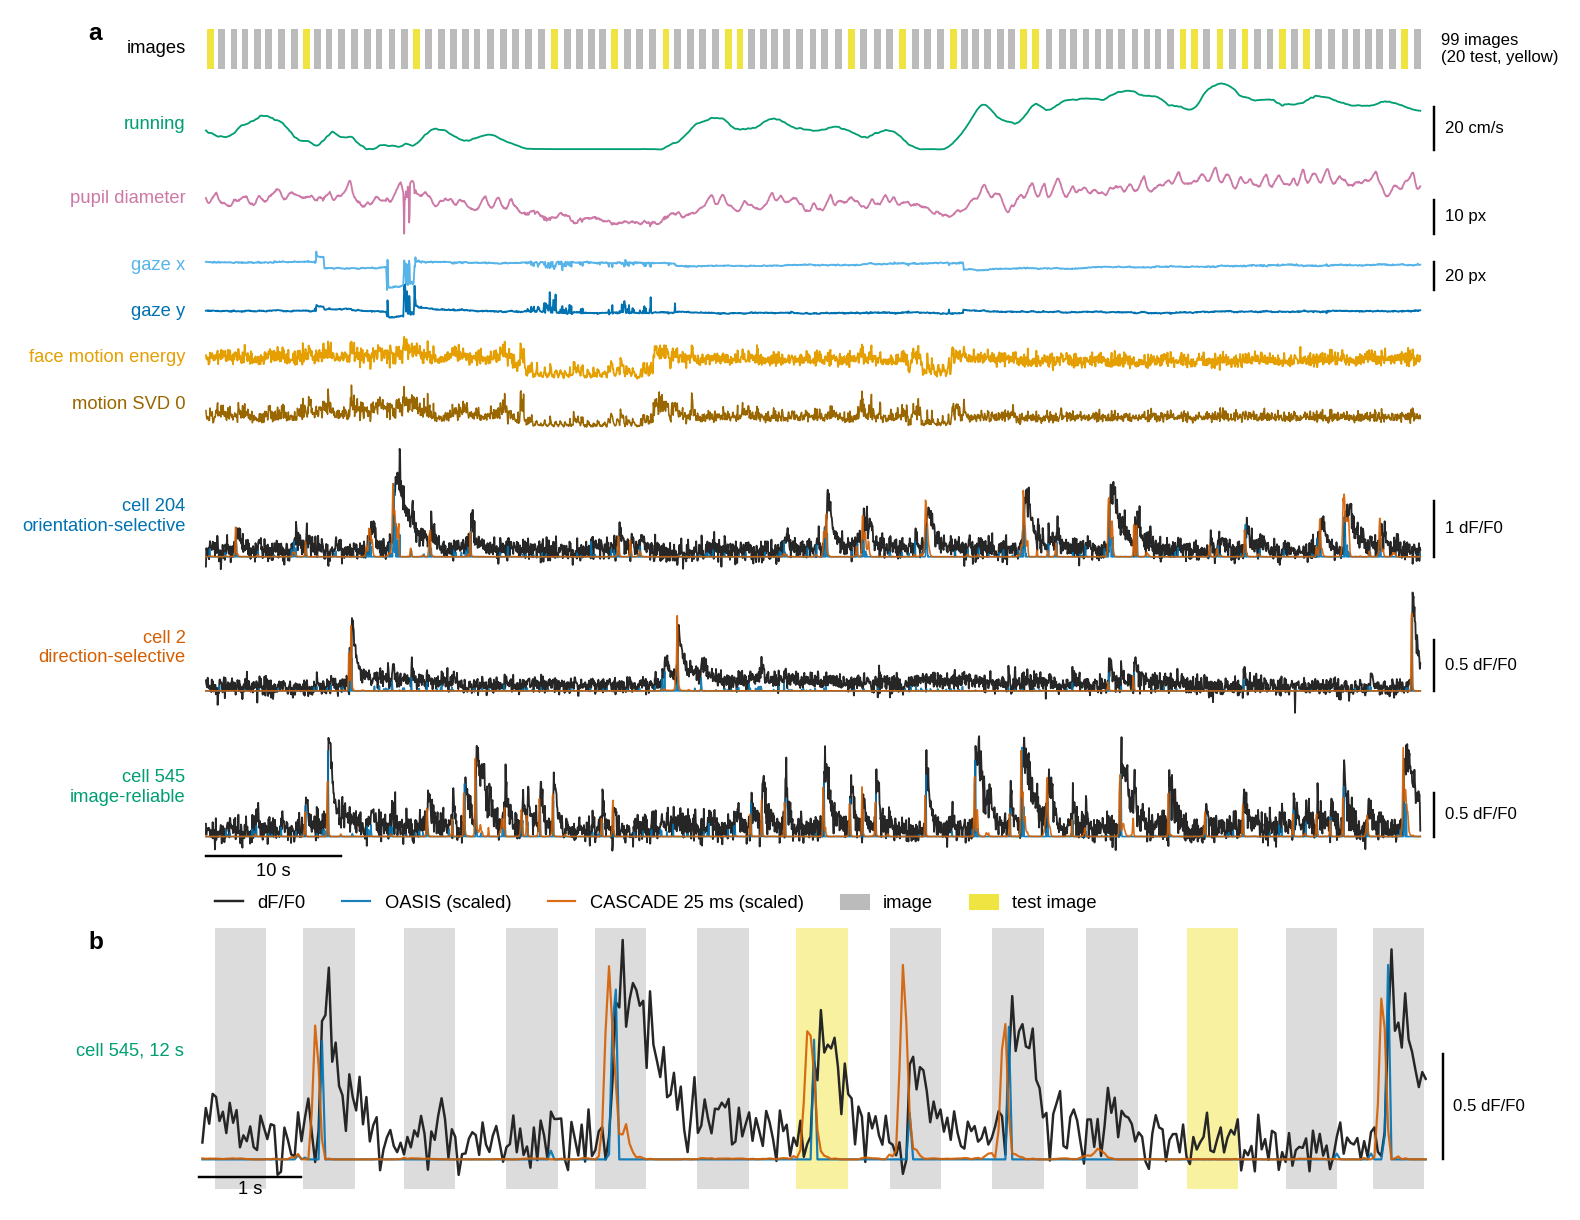

In [5]:
def zoom(ft, t0, dur):
    return slice(int(np.searchsorted(ft, t0)), int(np.searchsorted(ft, t0 + dur)))
# the 90 s with the most running variation that contain test images
starts = np.arange(ft_n[0] + 60, ft_n[-1] - 100, 15.0)
score = [np.nanstd(run_n[zoom(ft_n, s, 90)]) for s in starts]; t0 = starts[int(np.argmax(score))]
z = zoom(ft_n, t0, 90); tz = ft_n[z] - t0
def nice(x):
    for v in (0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50): 
        if v >= x: return v
    return 100
rows = [("stim", 0.3), ("run", 0.55), ("pupil", 0.55), ("gaze", 0.55), ("face", 0.75)] + [(f"cell{i}", 1.0) for i in range(3)]
fig = plt.figure(figsize=(W2, 0.95 * W2))
outer = fig.add_gridspec(2, 1, height_ratios=[3.2, 1], hspace=0.12)
axs = [fig.add_subplot(g) for g in outer[0].subgridspec(len(rows), 1, height_ratios=[h for _, h in rows], hspace=0.12)]
for a in axs[1:]: a.sharex(axs[0])
ax = axs[0]; panel(ax, "a", x=-0.09, y=0.6)
win = tr_n[(tr_n.t_on > t0) & (tr_n.t_on < t0 + 90)]
for _, x in win.iterrows():
    ax.add_patch(Rectangle((x.t_on - t0, 0), x.t_off - x.t_on, 1, color=COL["test"] if x.tier == "test" else COL["stim"], lw=0))
clean(ax); ax.set_ylim(0, 1); ax.text(-1.5, 0.5, "images", ha="right", va="center", fontsize=6)
ax.text(91.5, 0.5, f"{len(win)} images\n({int((win.tier == 'test').sum())} test, yellow)", fontsize=5.5, va="center")
def row(ax, y, col, label, unit):
    ax.plot(tz, y, color=col, lw=0.6); clean(ax)
    ax.text(-1.5, np.nanmean(y), label, ha="right", va="center", fontsize=6, color=col)
    bar = nice(0.4 * np.nanmax(np.ptp(y[np.isfinite(y)]))); y0 = np.nanmin(y)
    ax.plot([91, 91], [y0, y0 + bar], color="k", lw=0.8, clip_on=False); ax.text(91.8, y0 + bar / 2, f"{bar:g} {unit}", fontsize=5.5, va="center")
row(axs[1], run_n[z], COL["run"], "running", "cm/s")
row(axs[2], P2["size"][z], COL["pupil"], "pupil diameter", "px")
ax = axs[3]; gxz, gyz = P2["gaze_x"][z] - np.nanmean(P2["gaze_x"][z]), P2["gaze_y"][z] - np.nanmean(P2["gaze_y"][z])
row(ax, gxz, COL["gaze"], "gaze x", "px"); ax.plot(tz, gyz - 1.2 * np.nanmax(np.ptp(gxz)), color="#0072B2", lw=0.6)
ax.text(-1.5, np.nanmean(gyz) - 1.2 * np.nanmax(np.ptp(gxz)), "gaze y", ha="right", va="center", fontsize=6, color="#0072B2")
ax = axs[4]; e = E2[z]; m0 = M2[z, 0]
ax.plot(tz, (e - e.min()) / np.ptp(e), color=COL["face"], lw=0.6); ax.plot(tz, (m0 - m0.min()) / np.ptp(m0) - 1.15, color="#996600", lw=0.5); clean(ax)
ax.text(-1.5, 0.5, "face motion energy", ha="right", va="center", fontsize=6, color=COL["face"]); ax.text(-1.5, -0.6, "motion SVD 0", ha="right", va="center", fontsize=6, color="#996600")
def overlay(ax, T, sl, x, lw=0.6):
    dff = T["dff"][sl]; pk_ = np.nanpercentile(dff, 99.9)
    ax.plot(x, dff, color="0.15", lw=lw, label="dF/F0")
    for key in ("oasis", "cascade"):
        y = T[key][sl]; mx = np.nanmax(y)
        ax.plot(x, y / mx * pk_ * 0.9 if mx > 0 else y, color=COL[key], lw=lw * 0.9, alpha=0.9, label={"cascade": "CASCADE 25 ms (scaled)", "oasis": "OASIS (scaled)"}[key])
    return pk_
for k, (name, rw) in enumerate(EX.iterrows()):
    ax = axs[5 + k]; pk_ = overlay(ax, TN[name], z, tz); clean(ax)
    ax.text(-1.5, pk_ / 2, f"cell {int(rw.cell_index)}\n{name}", ha="right", va="center", fontsize=6, color=CELL_COL[k])
    bar = nice(0.4 * pk_); ax.plot([91, 91], [0, bar], color="k", lw=0.8, clip_on=False); ax.text(91.8, bar / 2, f"{bar:g} dF/F0", fontsize=5.5, va="center")
axs[-1].plot([0, 10], [axs[-1].get_ylim()[0]] * 2, color="k", lw=0.8, clip_on=False); axs[-1].text(5, axs[-1].get_ylim()[0], "10 s", ha="center", va="top", fontsize=6)
axs[0].set_xlim(-0.5, 90.5)
# b: 12-s zoom of the image-reliable cell, with the image onsets and read-out windows
k = 2; name = EX.index[k]; zb0 = t0 + float(np.clip(win.t_on.iloc[len(win) // 2] - t0 - 3, 0, 78))
zb = zoom(ft_n, zb0, 12); tb = ft_n[zb] - zb0
ax = fig.add_subplot(outer[1]); panel(ax, "b", x=-0.09, y=0.9)
for _, x in tr_n[(tr_n.t_on > zb0) & (tr_n.t_on < zb0 + 12)].iterrows():
    ax.axvspan(x.t_on - zb0, x.t_off - zb0, color=COL["test"] if x.tier == "test" else COL["stim"], alpha=0.5, lw=0)
pk_ = overlay(ax, TN[name], zb, tb, lw=0.8); clean(ax); ax.set_xlim(0, 12)
ax.legend(loc="lower left", ncol=5, bbox_to_anchor=(0, 1.0), handlelength=1.5,
          handles=ax.get_lines()[:3] + [Rectangle((0, 0), 1, 1, color=COL["stim"]), Rectangle((0, 0), 1, 1, color=COL["test"])],
          labels=["dF/F0", "OASIS (scaled)", "CASCADE 25 ms (scaled)", "image", "test image"])
bar = nice(0.4 * pk_); ax.plot([12.15, 12.15], [0, bar], color="k", lw=0.8, clip_on=False); ax.text(12.25, bar / 2, f"{bar:g} dF/F0", fontsize=5.5, va="center")
ax.plot([0, 1], [-0.08 * pk_] * 2, color="k", lw=0.8, clip_on=False); ax.text(0.5, -0.1 * pk_, "1 s", ha="center", va="top", fontsize=6)
ax.text(-0.15, pk_ / 2, f"cell {int(EX.iloc[k].cell_index)}, 12 s", ha="right", va="center", fontsize=6, color=CELL_COL[k])
save(fig, "fig2_timeline"); plt.show()

## Figure 3 · How a response is measured: the read-out windows

A response is the mean of a trace over a **response window** set by the stimulus; some read-outs also compare it with
a **baseline window** before the stimulus. Each read-out is one row of `responsiveness.ReadoutParamSet`, never
changed (a new window is a new `readout_idx`). The standard ones:

| `readout_idx` | used for | response window | baseline | why |
|---|---|---|---|---|
| 3 | images, OASIS (the export) | frames [on + 3, on + 3 + n), n = off − on + 2 of the first trial | — | +3 frames (0.1 s): calcium and display delay |
| 11 | images, CASCADE | frames [on − 1, on + 15) | — | CASCADE's kernel is non-causal: its rate rises 1 frame early |
| 16 | gratings, all traces | frames [on, off): the stimulus on screen (photodiode time) | frames [on − 60, on − 10) = −2.0 to −0.33 s (test only) | after the previous stimulus' OFF response, before CASCADE's early rise |

**a**, One natural-image presentation of the image-reliable example cell: the image on screen (grey), the read-out-3
window on OASIS (blue band), the read-out-11 window on CASCADE (vermillion band). **b**, One grating presentation of
the direction-selective cell: the read-out-16 response window (grey) and baseline window (hatched). The value stored
per trial is `Readout.Cell.trial_resp` (and `trial_base`); the dots mark it.

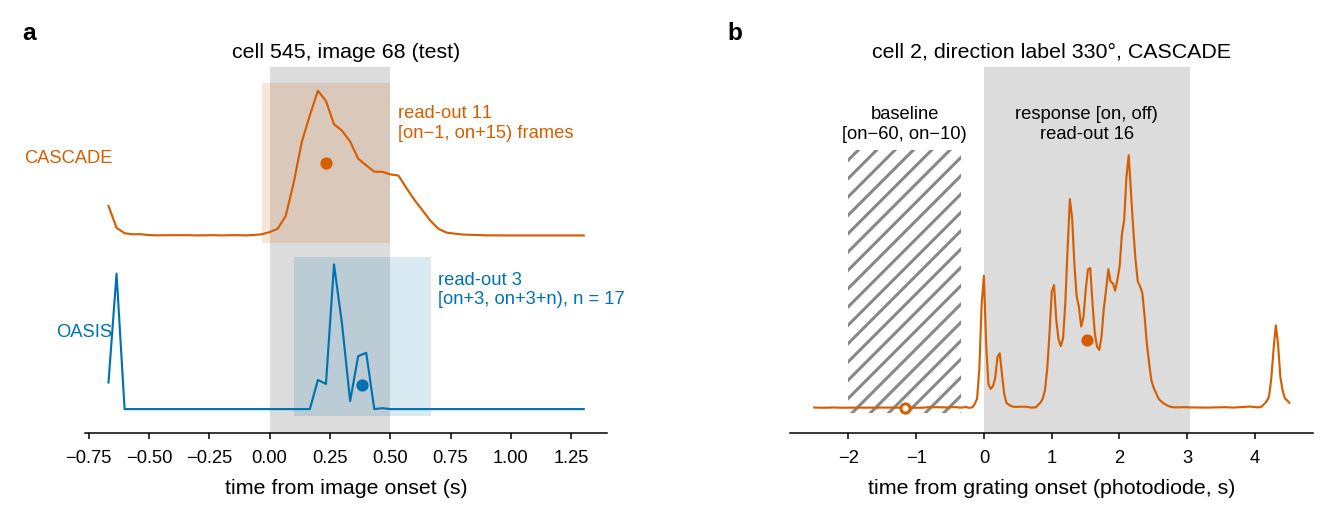

3 Leon export, natural images (v1-drift-audit 84/84): frames [on + 3, on + 3 + n), n = off - on + 2 of the first trial; DataJoint event time (+3 frames = display latency); no baseline; raw mean
11 CASCADE images (v1-drift-audit q1 consensus window, leave-one-animal-out on the oracle): frames [on - 1, on + 15); DataJoint event time; raw mean, no baseline (starts 1 frame early: CASCADE's non-causal kernel)
16 gratings standard: response = stimulus on screen, frames [on, off), RAW per-trial value; baseline (test only) = frames [on - 60, on - 10) = -2.0 to -0.33 s: after the previous stimulus' OFF response has decayed (< 10 percent from -63 frames on for dF/F0, the slowest trace) and before CASCADE's non-causal pre-onset rise (from -7 frames); screen time; t-test


In [6]:
ro = {r_["readout_idx"]: r_ for r_ in (resp.ReadoutParamSet & "readout_idx in (3, 11, 16)").fetch(as_dict=True)}
fig, axs = plt.subplots(1, 2, figsize=(W2, 0.3 * W2), gridspec_kw=dict(wspace=0.35))
# a: image trial
name = "image-reliable"; T = TN[name]; i_tr = int(np.argmax([T["cascade"][on - 1:on + 15].mean() if tr_n.tier[i] == "test" else -1 for i, on in enumerate(tr_n.on_frame)]))
on, off = int(tr_n.on_frame[i_tr]), int(tr_n.off_frame[i_tr]); f = np.arange(on - 20, on + 40); t = ft_n[f] - ft_n[on]
ax = axs[0]; panel(ax, "a", x=-0.12)
ax.axvspan(0, ft_n[off] - ft_n[on], color=COL["stim"], alpha=0.5, lw=0, label="image on screen")
w3 = (ft_n[on + 3] - ft_n[on], ft_n[on + 3 + n_win] - ft_n[on]); w11 = (ft_n[on - 1] - ft_n[on], ft_n[on + 15] - ft_n[on])
c = T["cascade"][f] / T["cascade"][f].max(); o = T["oasis"][f] / max(T["oasis"][f].max(), 1e-9)
ax.plot(t, c + 1.2, color=COL["cascade"]); ax.plot(t, o, color=COL["oasis"])
ax.add_patch(Rectangle((w11[0], 1.15), w11[1] - w11[0], 1.1, color=COL["cascade"], alpha=0.15, lw=0))
ax.add_patch(Rectangle((w3[0], -0.05), w3[1] - w3[0], 1.1, color=COL["oasis"], alpha=0.15, lw=0))
ax.plot(np.mean(w11), T["cascade"][on - 1:on + 15].mean() / T["cascade"][f].max() + 1.2, "o", color=COL["cascade"], ms=3)
ax.plot(np.mean(w3), T["oasis"][on + 3:on + 3 + n_win].mean() / max(T["oasis"][f].max(), 1e-9), "o", color=COL["oasis"], ms=3)
ax.text(w11[1] + 0.03, 2.1, "read-out 11\n[on−1, on+15) frames", color=COL["cascade"], fontsize=6, va="top")
ax.text(w3[1] + 0.03, 0.95, f"read-out 3\n[on+3, on+3+n), n = {n_win}", color=COL["oasis"], fontsize=6, va="top")
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlabel("time from image onset (s)")
ax.text(-0.65, 1.7, "CASCADE", color=COL["cascade"], fontsize=6, ha="right"); ax.text(-0.65, 0.5, "OASIS", color=COL["oasis"], fontsize=6, ha="right")
ax.set_title(f"cell {int(EX.loc[name, 'cell_index'])}, image {tr_n.image_id[i_tr]} (test)")
# b: grating trial with read-out 16 windows
name = "direction-selective"; T = TG[name]
on_g = resp.EventSet.Onset & cur_g & {"event_selector": "gratings"}
og = pd.DataFrame(on_g.fetch("onset_idx", "condition", "event_start_time", "shift_s", as_dict=True)).sort_values("onset_idx")
st = pd.DataFrame((resp.ScreenTiming.Onset & cur_g & {"event_selector": "gratings"}).fetch("event_start_time", "diode_on", "diode_off", as_dict=True))
og = og.merge(st, on="event_start_time", how="left")
og["t_on"] = og.diode_on.astype(float).fillna(og.event_start_time.astype(float) + og.shift_s)
og["on_f"] = nearest_frame(og.t_on.to_numpy(), ft_g); og["off_f"] = nearest_frame(og.diode_off.astype(float).to_numpy(), ft_g)
trial_resp, trial_base = (resp.Readout.Cell & cur_g & GK & {"mask": int(EX.loc[name, "mask_g"])}).fetch1("trial_resp", "trial_base")
best_dir = og.condition.iloc[int(np.nanargmax(trial_resp))]; j = int(np.nanargmax(trial_resp))
on, off = int(og.on_f.iloc[j]), int(og.off_f.iloc[j]); f = np.arange(on - 75, min(off + 45, len(ft_g))); t = ft_g[f] - ft_g[on]
ax = axs[1]; panel(ax, "b", x=-0.12)
ax.axvspan(0, ft_g[off] - ft_g[on], color=COL["stim"], alpha=0.5, lw=0)
ax.add_patch(Rectangle((ft_g[on - 60] - ft_g[on], -0.02), ft_g[on - 10] - ft_g[on - 60], 1.04, fill=False, hatch="////", ec=COL["grey"], lw=0))
y = T["cascade"][f]; ax.plot(t, y / y.max(), color=COL["cascade"])
ax.plot((ft_g[off] - ft_g[on]) / 2, trial_resp[j] / y.max(), "o", color=COL["cascade"], ms=3)
ax.plot((ft_g[on - 60] + ft_g[on - 10]) / 2 - ft_g[on], trial_base[j] / y.max(), "o", mfc="w", mec=COL["cascade"], ms=3)
ax.text((ft_g[on - 60] + ft_g[on - 10]) / 2 - ft_g[on], 1.05, "baseline\n[on−60, on−10)", ha="center", fontsize=6, va="bottom")
ax.text((ft_g[off] - ft_g[on]) / 2, 1.05, "response [on, off)\nread-out 16", ha="center", fontsize=6, va="bottom")
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlabel("time from grating onset (photodiode, s)"); ax.set_ylim(-0.1, 1.35)
ax.set_title(f"cell {int(EX.loc[name, 'cell_index'])}, direction label {best_dir}°, CASCADE")
save(fig, "fig3_windows"); plt.show()
for k in (3, 11, 16): print(k, ro[k]["readout_desc"])

## Figure 4 · Natural-image responses

The 100 **test images** are shown 10 times in every session (event selector `nat_images_repeated`); repeats measure
reliability. Read-out 11 (CASCADE). **a**, Responses of the image-reliable cell to every test image (columns, sorted by
the mean) and repeat (rows): `Readout.Cell.trial_resp`. **b**, Mean CASCADE rate around the onset of its three best
images (± s.e.m. across the 10 repeats), with the images. **c**, Reliability: each repeat against the mean of the
other nine (leave-one-out), whose correlation is the **oracle** (`oracle_r`). The box lists the cell's other measures:

* `zeta_p`: ZETA test (Montijn et al. 2021), any response shape, from the time-locked spike rate; `zeta_idx` 1;
* `fev`: fraction of explainable variance (signal variance / total variance across repeats);
* `lifetime_sparseness`: how few images drive the cell (0 = all equally, 1 = one image).

**d**, All neurons of the recording: oracle against ZETA; dashed lines = the lab's rule for images
(`oracle_r` ≥ 0.08, `zeta_p` < 0.001); the examples in colour.

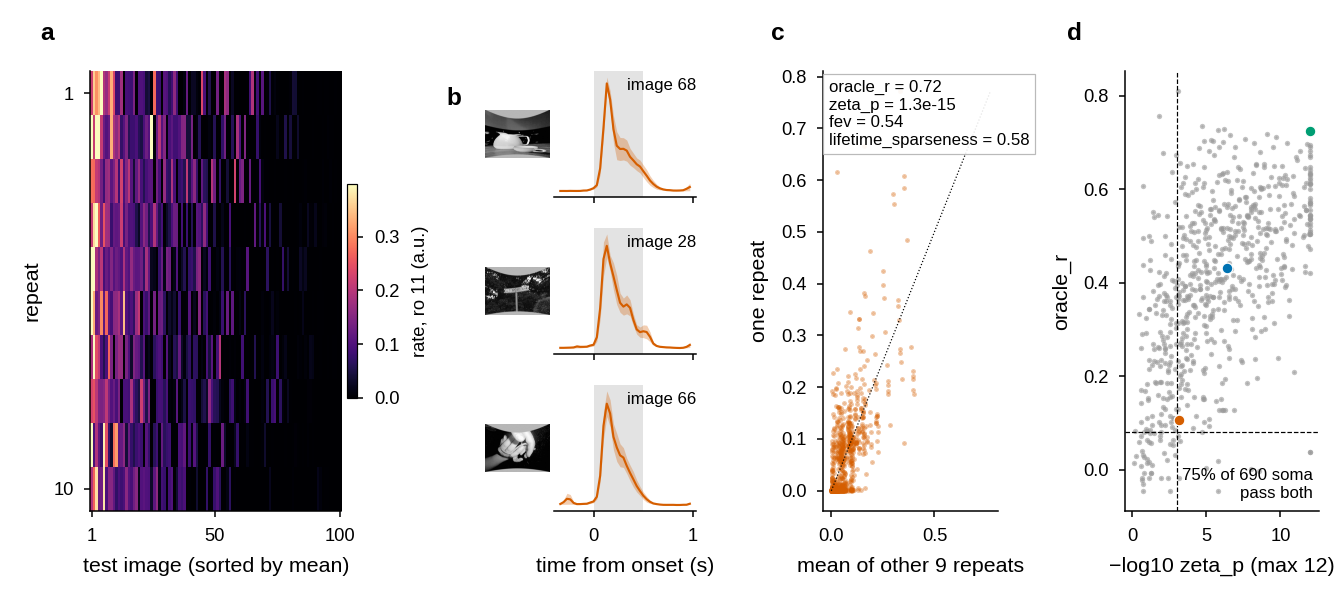

In [7]:
name = "image-reliable"; mk = int(EX.loc[name, "mask_n"])
on_n = pd.DataFrame((resp.EventSet.Onset & cur_n & {"event_selector": NK["event_selector"]}).fetch("onset_idx", "condition", "event_start_time", as_dict=True)).sort_values("onset_idx")
rowc = (resp.Readout.Cell & cur_n & NK & {"mask": mk}).fetch1()
zc = (resp.Zeta.Cell & cur_n & NK & {"zeta_idx": 1, "mask": mk}).fetch1()
tr = np.asarray(rowc["trial_resp"], float); on_n["resp"] = tr; on_n["rep"] = on_n.groupby("condition").cumcount()
M = on_n.pivot(index="rep", columns="condition", values="resp"); M = M[M.mean().sort_values(ascending=False).index]
fig = plt.figure(figsize=(W2, 0.36 * W2)); gs = fig.add_gridspec(1, 4, width_ratios=[1.45, 1.15, 0.95, 1.05], wspace=0.6)
ax = fig.add_subplot(gs[0]); panel(ax, "a", x=-0.2)
im_ = ax.imshow(M.to_numpy(), aspect="auto", cmap="magma", interpolation="nearest", vmin=0, vmax=np.nanpercentile(M.to_numpy(), 99)); ax.set_xlabel("test image (sorted by mean)"); ax.set_ylabel("repeat")
ax.set_xticks([0, 49, 99]); ax.set_xticklabels([1, 50, 100]); ax.set_yticks([0, 9]); ax.set_yticklabels([1, 10])
cb = fig.colorbar(im_, ax=ax, fraction=0.04, pad=0.02); cb.set_label("rate, ro 11 (a.u.)", fontsize=6); cb.outline.set_linewidth(0.4)
# b: PSTH of the three best images
sub = gs[1].subgridspec(3, 2, width_ratios=[0.45, 1], hspace=0.25, wspace=0.05)
cas = TN[name]["cascade"]
for k, img_id in enumerate(M.columns[:3]):
    onsets = tr_n[tr_n.image_id == int(img_id)].on_frame.to_numpy()
    seg = np.stack([cas[o - 10:o + 30] for o in onsets]); tt = (np.arange(-10, 30)) / 30.0
    axi = fig.add_subplot(sub[k, 0]); axi.imshow(load_image(int(img_id))[0], cmap="gray"); clean(axi)
    if k == 0: panel(axi, "b", x=-0.6, y=1.0)
    axp = fig.add_subplot(sub[k, 1]); m_, s_ = seg.mean(0), seg.std(0) / np.sqrt(len(seg))
    axp.axvspan(0, 0.5, color=COL["stim"], alpha=0.4, lw=0); axp.fill_between(tt, m_ - s_, m_ + s_, color=COL["cascade"], alpha=0.3, lw=0)
    axp.plot(tt, m_, color=COL["cascade"]); axp.set_yticks([]); axp.spines["left"].set_visible(False)
    axp.text(1.0, 0.85, f"image {img_id}", transform=axp.transAxes, ha="right", fontsize=5.5)
    if k < 2: axp.set_xticklabels([])
    else: axp.set_xlabel("time from onset (s)")
# c: leave-one-out reliability
ax = fig.add_subplot(gs[2]); panel(ax, "c", x=-0.3)
A = M.to_numpy()
for r_ in range(A.shape[0]):
    others = np.nanmean(np.delete(A, r_, 0), 0); ax.plot(others, A[r_], ".", ms=1.2, color=COL["cascade"], alpha=0.35)
lim = np.nanmax(A); ax.plot([0, lim], [0, lim], color="k", lw=0.4, ls=":"); ax.set_xlabel("mean of other 9 repeats"); ax.set_ylabel("one repeat")
ax.text(0.03, 0.98, f"oracle_r = {rowc['oracle_r']:.2f}\nzeta_p = {zc['zeta_p']:.1e}\nfev = {rowc['fev']:.2f}\n"
        f"lifetime_sparseness = {rowc['lifetime_sparseness']:.2f}",
        transform=ax.transAxes, fontsize=5.5, va="top", ha="left", bbox=dict(fc="w", ec="0.7", lw=0.4, pad=2, alpha=0.9))
# d: population
ax = fig.add_subplot(gs[3]); panel(ax, "d", x=-0.3)
pop = pd.DataFrame((resp.Readout.Cell * resp.Zeta.Cell & cur_n & NK & {"zeta_idx": 1} & soma_query(cur_n).proj()).fetch("mask", "oracle_r", "zeta_p", as_dict=True))
pop = pop[~pop["mask"].isin(rej_n)]
ax.plot(-np.log10(pop.zeta_p.clip(lower=1e-12)), pop.oracle_r, ".", ms=1.5, color="0.6", alpha=0.6)
ax.axhline(0.08, color="k", ls="--", lw=0.4); ax.axvline(3, color="k", ls="--", lw=0.4)
for c, (nm, r_) in zip(CELL_COL, EX.iterrows()):
    p = pop[pop["mask"] == r_.mask_n]; ax.plot(-np.log10(p.zeta_p.clip(lower=1e-12)), p.oracle_r, "o", ms=3.5, color=c, mec="w", mew=0.4)
ok = ((pop.oracle_r >= 0.08) & (pop.zeta_p < 1e-3)).mean()
ax.set_xlabel("−log10 zeta_p (max 12)"); ax.set_ylabel("oracle_r"); ax.text(0.97, 0.03, f"{100 * ok:.0f}% of {len(pop)} soma\npass both", transform=ax.transAxes, ha="right", fontsize=5.5)
save(fig, "fig4_images"); plt.show()

## Figure 5 · Gratings: responses, tuning and the levels of tuning

Drifting gratings, 12 directions × 15 repeats, read-out 16 (CASCADE; raw mean over the stimulus). Angles follow the
agreed convention (`tuning_idx` 1): the stored label L is the motion direction, clockwise; the tuning angle is
θ = (90 − L) mod 360, so `pref_ori` is the **bar orientation** (0° horizontal, 90° vertical) and `pref_dir` is the
motion direction + 90°.

**a**, Mean CASCADE rate of the two tuned example cells for each direction (± s.e.m. over repeats; grey: grating on
screen). **b**, Tuning curves: condition means (`Readout.Condition.resp` ± `resp_sem`) and the fitted double Gaussian
R(θ) = C + Rp·exp(−Δ(θ − θp)² / 2σ²) + Rn·exp(−Δ(θ − θp + 180)² / 2σ²) (`fit_*`), with its goodness of fit:
`fit_r2_cv` (cross-validated r²) and `fit_chi2_p` (χ² test of the residuals; fits are reported only where
`hotelling_p` < 0.05, `fit_r2_cv` > 0.5 and `fit_chi2_p` > 0.05). **c**, The same as polar plots, with the vector
sums whose lengths are the global indices:

* `gosi` = 1 − circular variance = |Σ R_k e^{2iθ_k}| / Σ R_k (orientation), `gdsi` = |Σ R_k e^{iθ_k}| / Σ R_k (direction);
* classic point indices: `osi` = (Rp − Rorth)/(Rp + Rorth), `dsi` = (Rp − Rnull)/(Rp + Rnull), `oi`, `di`;
* `hotelling_p`: Hotelling's T² test that the trial vectors in orientation space differ from zero (Mazurek 2014).

**d**, **Levels of tuning** across all soma of the recording: `gosi` against `gdsi`. Grey: not significantly tuned
(`hotelling_p` ≥ 0.05); black: tuned. Guide lines at 0.2 and 0.4 mark weak, moderate and strong selectivity
(conventional levels, not a lab rule; the split-half `gosi_cv` ≤ 0 means no reliable tuning at all).
**e**, Preferred orientations of the tuned cells with a good fit.

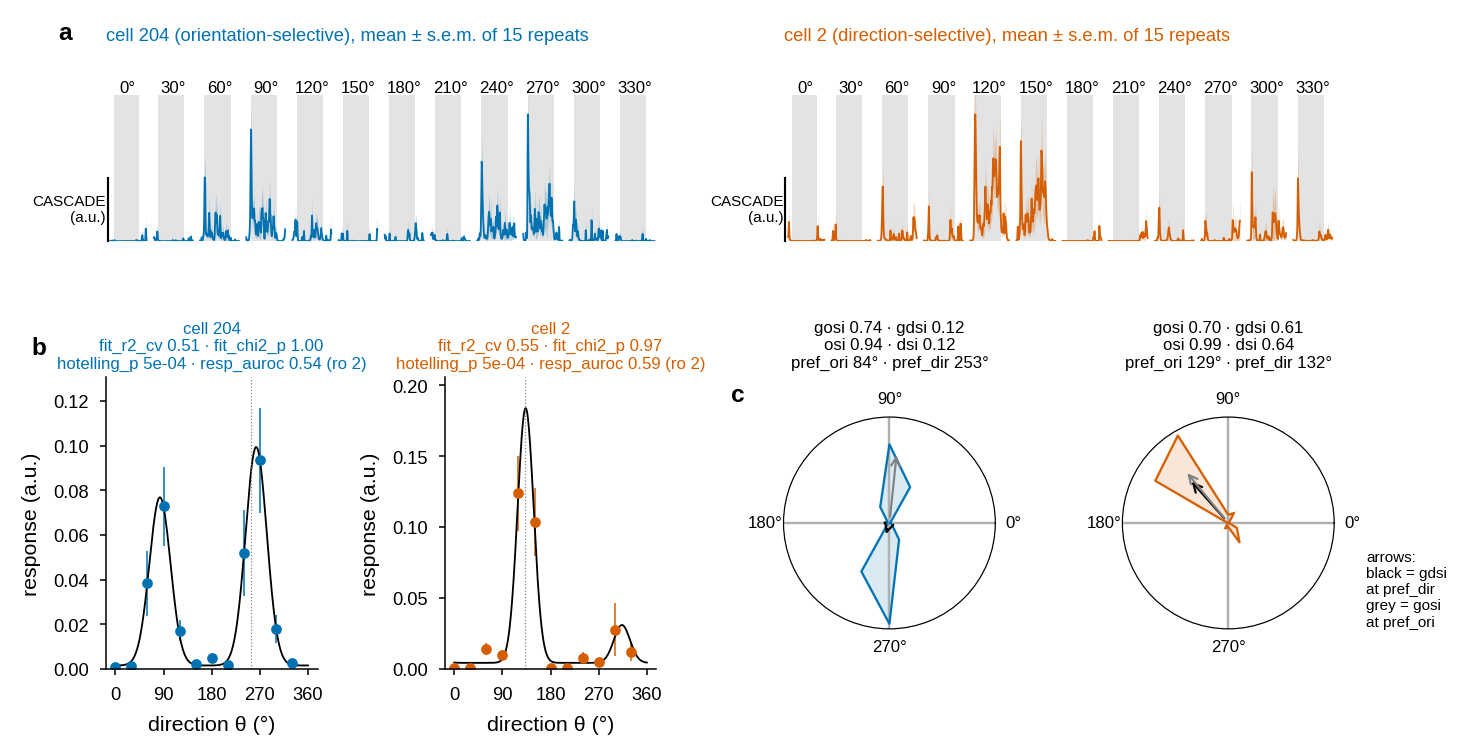

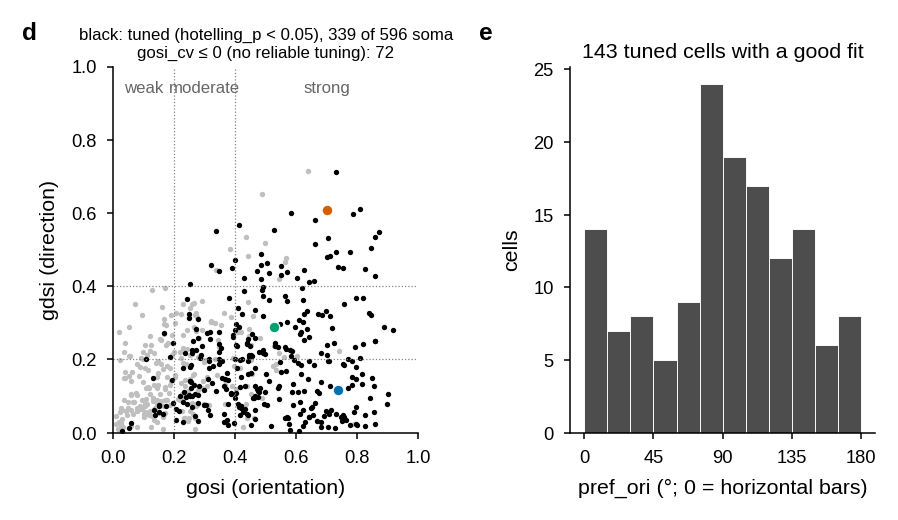

In [8]:
def theta(L): return (90.0 - np.asarray(L, float)) % 360.0
def dgauss(th, p):
    d = lambda x: (x + 180) % 360 - 180
    return p["fit_c"] + p["fit_rp"] * np.exp(-d(th - p["fit_pref_dir"]) ** 2 / (2 * p["fit_sigma"] ** 2)) + p["fit_rn"] * np.exp(-d(th - p["fit_pref_dir"] + 180) ** 2 / (2 * p["fit_sigma"] ** 2))
fig = plt.figure(figsize=(W2, 0.47 * W2)); gs = fig.add_gridspec(2, 4, height_ratios=[0.5, 1], hspace=0.62, wspace=0.6)
dirs = sorted(og.condition.unique(), key=lambda s: theta(float(s)))
for k, name in enumerate(["orientation-selective", "direction-selective"]):
    T = TG[name]["cascade"]; row = EX.loc[name]
    sub = gs[0, 2 * k:2 * k + 2].subgridspec(1, len(dirs), wspace=0.08)
    seg_max = 0; segs = {}
    for d in dirs:
        o = og[og.condition == d]; L = int(np.median(o.off_f - o.on_f))
        segs[d] = np.stack([T[a - 15:a + L + 30] for a in o.on_f]); seg_max = max(seg_max, segs[d].mean(0).max())
    for j, d in enumerate(dirs):
        ax = fig.add_subplot(sub[j]); s_ = segs[d]; tt = (np.arange(s_.shape[1]) - 15) / 30.0
        ax.axvspan(0, (s_.shape[1] - 45) / 30.0, color=COL["stim"], alpha=0.4, lw=0)
        m_, e_ = s_.mean(0), s_.std(0) / np.sqrt(len(s_)); ax.fill_between(tt, m_ - e_, m_ + e_, color=CELL_COL[k], alpha=0.25, lw=0)
        ax.plot(tt, m_, color=CELL_COL[k], lw=0.6); ax.set_ylim(0, seg_max * 1.15); clean(ax)
        ax.set_title(f"{theta(float(d)):.0f}°", fontsize=5.5, pad=1)
        if j == 0:
            if k == 0: panel(ax, "a", x=-1.1, y=1.35)
            ax.text(0, 1.38, f"cell {int(row.cell_index)} ({name}), mean ± s.e.m. of 15 repeats", transform=ax.transAxes, fontsize=6, color=CELL_COL[k])
            ax.plot([tt[0] - 0.3] * 2, [0, seg_max / 2], color="k", lw=0.7, clip_on=False)
            ax.text(tt[0] - 0.5, seg_max / 4, "CASCADE\n(a.u.)", ha="right", va="center", fontsize=5)
    # b: tuning curve
    ax = fig.add_subplot(gs[1, k]);
    if k == 0: panel(ax, "b", x=-0.35)
    cond = pd.DataFrame((resp.Readout.Condition & cur_g & GK & {"mask": int(row.mask_g)}).fetch("condition", "resp", "resp_sem", as_dict=True))
    cond["th"] = theta(cond.condition.astype(float)); cond = cond.sort_values("th")
    p = (resp.DirectionTuning.Cell & cur_g & GK & {"tuning_idx": 1, "mask": int(row.mask_g)}).fetch1()
    ax.errorbar(cond.th, cond.resp, yerr=cond.resp_sem, fmt="o", ms=2.5, color=CELL_COL[k], elinewidth=0.5, capsize=0)
    th_ = np.linspace(0, 360, 361); ax.plot(th_, dgauss(th_, p), color="k", lw=0.6)
    ax.axvline(p["pref_dir"], color="0.5", lw=0.4, ls=":"); ax.set_xticks([0, 90, 180, 270, 360]); ax.set_xlabel("direction θ (°)"); ax.set_ylabel("response (a.u.)")
    auroc2 = (resp.Readout.Cell & cur_g & dict(GK, readout_idx=2) & {"mask": int(row.mask_g)}).fetch1("resp_auroc")
    ax.set_title(f"cell {int(row.cell_index)}\nfit_r2_cv {p['fit_r2_cv']:.2f} · fit_chi2_p {p['fit_chi2_p']:.2f}\n"
                 f"hotelling_p {p['hotelling_p']:.0e} · resp_auroc {auroc2:.2f} (ro 2)", color=CELL_COL[k], fontsize=5.5)
    ax.set_ylim(0, 1.12 * max(np.nanmax(dgauss(th_, p)), np.nanmax(cond.resp + cond.resp_sem)))
    # c: polar
    axp = fig.add_subplot(gs[1, 2 + k] if False else gs[1, k + 2], projection="polar")
    if k == 0: panel(axp, "c", x=-0.25, y=1.05)
    r_ = np.clip(cond.resp.to_numpy(), 0, None); th_r = np.deg2rad(cond.th.to_numpy())
    axp.plot(np.r_[th_r, th_r[0]], np.r_[r_, r_[0]], color=CELL_COL[k], lw=0.7); axp.fill(np.r_[th_r, th_r[0]], np.r_[r_, r_[0]], color=CELL_COL[k], alpha=0.15)
    R = r_.max()
    axp.annotate("", xy=(np.deg2rad(p["pref_dir"]), p["gdsi"] * R), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=0.7))
    axp.annotate("", xy=(np.deg2rad(p["pref_ori"]), p["gosi"] * R), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="0.5", lw=0.7))
    axp.set_yticks([]); axp.set_xticks(np.deg2rad([0, 90, 180, 270])); axp.tick_params(pad=-3, labelsize=5.5); axp.spines["polar"].set_linewidth(0.4)
    axp.set_title(f"gosi {p['gosi']:.2f} · gdsi {p['gdsi']:.2f}\nosi {p['osi']:.2f} · dsi {p['dsi']:.2f}\npref_ori {p['pref_ori']:.0f}° · pref_dir {p['pref_dir']:.0f}°", fontsize=5.5, pad=8)
    if k == 1:
        axp.text(1.15, 0.0, "arrows:\nblack = gdsi\nat pref_dir\ngrey = gosi\nat pref_ori", transform=axp.transAxes, fontsize=5, va="bottom")
save(fig, "fig5a_gratings"); plt.show()

# d, e: levels of tuning across the recording
allt = pd.DataFrame((resp.DirectionTuning.Cell & cur_g & GK & {"tuning_idx": 1} & soma_query(cur_g).proj()).fetch(
    "mask", "gosi", "gdsi", "gosi_cv", "hotelling_p", "pref_ori", "fit_r2_cv", "fit_chi2_p", as_dict=True))
allt = allt[~allt["mask"].isin(rej_g)]; sig = allt.hotelling_p < 0.05
fig, axs = plt.subplots(1, 2, figsize=(W2 * 0.62, 0.3 * W2), gridspec_kw=dict(wspace=0.5))
ax = axs[0]; panel(ax, "d", x=-0.3)
ax.plot(allt.gosi[~sig], allt.gdsi[~sig], ".", ms=1.5, color="0.75"); ax.plot(allt.gosi[sig], allt.gdsi[sig], ".", ms=1.5, color="k")
for c, (nm, r_) in zip(CELL_COL, EX.iterrows()):
    q = allt[allt["mask"] == r_.mask_g]; ax.plot(q.gosi, q.gdsi, "o", ms=3.5, color=c, mec="w", mew=0.4)
for v in (0.2, 0.4): ax.axvline(v, color="0.5", lw=0.4, ls=":"); ax.axhline(v, color="0.5", lw=0.4, ls=":")
for xx, lab in [(0.1, "weak"), (0.3, "moderate"), (0.7, "strong")]: ax.text(xx, 0.93, lab, fontsize=5.5, ha="center", color="0.4")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("gosi (orientation)"); ax.set_ylabel("gdsi (direction)")
ax.set_title(f"black: tuned (hotelling_p < 0.05), {sig.sum()} of {len(allt)} soma\ngosi_cv ≤ 0 (no reliable tuning): {int((allt.gosi_cv <= 0).sum())}", fontsize=5.5)
ax = axs[1]; panel(ax, "e", x=-0.3)
fitok = sig & (allt.fit_r2_cv > 0.5) & (allt.fit_chi2_p > 0.05)
ax.hist(allt.pref_ori[fitok], bins=np.arange(0, 181, 15), color="0.3", ec="w", lw=0.3)
ax.set_xticks([0, 45, 90, 135, 180]); ax.set_xlabel("pref_ori (°; 0 = horizontal bars)"); ax.set_ylabel("cells"); ax.set_title(f"{int(fitok.sum())} tuned cells with a good fit")
save(fig, "fig5b_tuning_levels"); plt.show()

## Figure 6 · Quality measures

Every measure of `roselab_responsiveness`'s quality tables, for every soma of the natural-image recording, with the
example cells marked. Dashed lines: thresholds of the lab's cell rules (`CellRule`), where one exists.

| measure | table | definition |
|---|---|---|
| `kurtosis` | `Quality.Cell` | excess kurtosis of F: sparse, spiking cells are high; neuropil-like ROIs near 0 |
| `neuropil_r` | `Quality.Cell` | correlation of F with its neuropil: high = contaminated |
| `photons_per_s` | `Quality.Cell` | mean photon flux of the ROI, from the detector gain (`ScanQuality.gain`) |
| `snr_s2p` | `TraceQuality.Cell` | suite2p's signal-to-noise of the trace (per trace type) |
| `event_rate` | `TraceQuality.Cell` | rate of inferred events (Hz) |
| `oracle_r` | `Readout.Cell` | leave-one-out correlation over repeats (fig. 4c); rule: ≥ 0.08 (images), ≥ 0.18 (gratings) |
| `zeta_p` | `Zeta.Cell` | ZETA test; rule for images: < 0.001 |
| `snr_s2p` (dF/F0) | `TraceQuality.Cell` | the same SNR for dF/F0; dashed: the top-quarter bar used for the example cells |
| `resp_auroc` | `Readout.Cell` | response vs baseline ROC area; stored for read-out 2 (gratings, fig. 5) |
| ROI QC | `imaging.RoiQC.Rejected` | `empty_f` (no own pixels), `second_channel`; such ROIs are excluded |

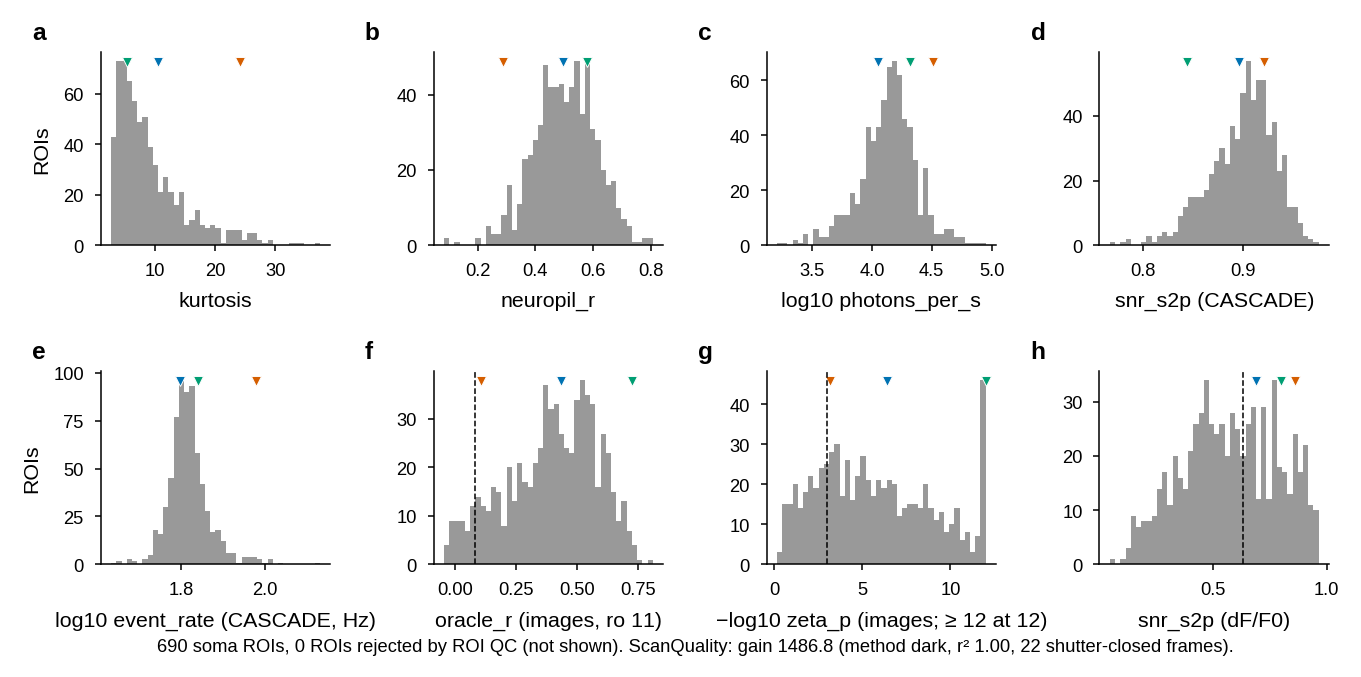

In [9]:
sq = (resp.ScanQuality & NI).fetch1()
qc = pd.DataFrame((resp.Quality.Cell & cur_n).fetch("mask", "kurtosis", "neuropil_r", "photons_per_s", as_dict=True))
tq_all = pd.DataFrame((resp.TraceQuality.Cell & cur_n).fetch("mask", "trace_source", "snr_s2p", "event_rate", as_dict=True))
ro11 = pd.DataFrame((resp.Readout.Cell & cur_n & NK).fetch("mask", "oracle_r", as_dict=True)); zz = pd.DataFrame((resp.Zeta.Cell & cur_n & NK & {"zeta_idx": 1}).fetch("mask", "zeta_p", as_dict=True))
keep = lambda df: df[df["mask"].isin(soma_n) & ~df["mask"].isin(rej_n)]
panels = [(keep(qc), "kurtosis", "kurtosis", None, False), (keep(qc), "neuropil_r", "neuropil_r", None, False),
          (keep(qc), "photons_per_s", "photons_per_s", None, True),
          (keep(tq_all[tq_all.trace_source == "cascade25"]), "snr_s2p", "snr_s2p (CASCADE)", None, False),
          (keep(tq_all[tq_all.trace_source == "cascade25"]), "event_rate", "event_rate (CASCADE, Hz)", None, True),
          (keep(ro11), "oracle_r", "oracle_r (images, ro 11)", 0.08, False), (keep(zz), "zeta_p", "−log10 zeta_p (images; ≥ 12 at 12)", 3, "zeta"),
          (keep(tq_all[tq_all.trace_source == "dff0_r2"]), "snr_s2p", "snr_s2p (dF/F0)", SNR_DFF_MIN, False)]
fig, axs = plt.subplots(2, 4, figsize=(W2, 0.42 * W2), gridspec_kw=dict(hspace=0.65, wspace=0.45))
for k, (ax, (df, col, label, thr, logx)) in enumerate(zip(axs.flat, panels)):
    panel(ax, "abcdefgh"[k], x=-0.3, y=1.04)
    v = df[col].astype(float)
    if logx == "zeta": v = -np.log10(v.clip(lower=1e-12))
    elif logx: v = np.log10(v.clip(lower=1e-6))
    ax.hist(v.dropna(), bins=40, color="0.6", lw=0)
    for c, (nm, r_) in zip(CELL_COL, EX.iterrows()):
        x = v[df["mask"].to_numpy() == r_.mask_n]
        if len(x): ax.plot(x.iloc[0], ax.get_ylim()[1] * 0.95, "v", color=c, ms=3.5, mec="w", mew=0.3)
    if thr is not None: ax.axvline(thr, color="k", ls="--", lw=0.5)
    ax.set_xlabel(("log10 " if logx is True else "") + label); ax.set_ylabel("ROIs" if k % 4 == 0 else "")
fig.text(0.5, -0.02, f"{len(soma_n)} soma ROIs, {len(rej_n)} ROIs rejected by ROI QC (not shown). ScanQuality: gain {sq['gain']:.1f} "
         f"(method {sq['gain_method']}, r² {sq['gain_r2']:.2f}, {sq['n_dark_frames']} shutter-closed frames).", ha="center", fontsize=6)
save(fig, "fig6_quality"); plt.show()

## Figure 7 · Responses, running and pupil

What the drift model sees per trial: the response (read-out 3, OASIS, as exported) and the behaviour vector. **a**,
Running speed and pupil diameter per trial over the recording (mean over the trial window). **b**, The image-reliable
cell's response to the test images, split by running (> 1 cm/s) and stillness: mean over repeats per image, running
against still; points above the diagonal = larger responses during running. **c**, The same split for the whole
population: the ratio of each reliable cell's mean response when running vs still (log2), and the correlation of the
per-trial response with pupil size within each test image (mean over images).

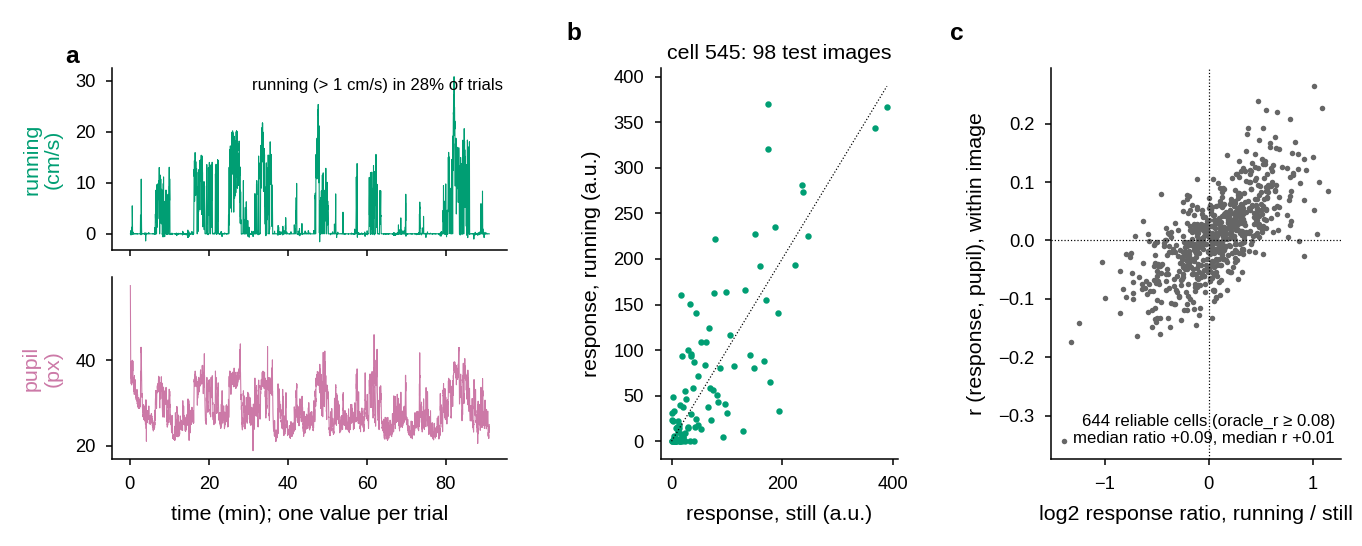

figures written to /home/backup_user/drift_example_figures


In [10]:
bwin = window_index(tr_n.on_frame, BEHAVIOR_OFFSET, n_win); rwin = window_index(tr_n.on_frame, RESPONSE_OFFSET, n_win)
run_tr, pup_tr = run_n[bwin].mean(1), P2["size"][bwin].mean(1)
act_n = activity(cur_n); cells_n = cells_of(cur_n); R = act_n[:, rwin].mean(-1).T; del act_n
fig = plt.figure(figsize=(W2, 0.32 * W2)); gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 0.9, 1.1], wspace=0.5)
sub = gs[0].subgridspec(2, 1, hspace=0.15)
tt = ft_n[tr_n.on_frame.to_numpy()] / 60; moving = run_tr > 1.0
ax = fig.add_subplot(sub[0]); panel(ax, "a", x=-0.12, y=1.0)
ax.plot(tt, run_tr, color=COL["run"], lw=0.35); ax.set_ylabel("running\n(cm/s)", color=COL["run"]); ax.tick_params(labelbottom=False)
ax.text(0.99, 0.95, f"running (> 1 cm/s) in {100 * moving.mean():.0f}% of trials", transform=ax.transAxes, fontsize=5.5, ha="right", va="top")
ax = fig.add_subplot(sub[1], sharex=ax); ax.plot(tt, pup_tr, color=COL["pupil"], lw=0.35); ax.set_ylabel("pupil\n(px)", color=COL["pupil"]); ax.set_xlabel("time (min); one value per trial")
ax = fig.add_subplot(gs[1]); panel(ax, "b", x=-0.4)
j = int(np.where(cells_n["mask"] == EX.loc["image-reliable", "mask_n"])[0][0]); test = (tr_n.tier == "test").to_numpy()
df = pd.DataFrame({"img": tr_n.image_id[test].to_numpy(), "r": R[test, j], "mv": moving[test]})
g = df.groupby(["img", "mv"]).r.mean().unstack().dropna()
ax.plot(g[False], g[True], ".", ms=2.2, color=CELL_COL[2]); lim = max(g.max().max(), 1e-6); ax.plot([0, lim], [0, lim], "k:", lw=0.4)
ax.set_xlabel("response, still (a.u.)"); ax.set_ylabel("response, running (a.u.)"); ax.set_title(f"cell {int(EX.loc['image-reliable', 'cell_index'])}: {len(g)} test images")
ax = fig.add_subplot(gs[2]); panel(ax, "c", x=-0.35)
rel = keep(ro11)[keep(ro11).oracle_r >= 0.08]["mask"].to_numpy(); idx = np.where(cells_n["mask"].isin(rel))[0]
ratio = np.log2((R[test][moving[test]][:, idx].mean(0) + 1e-3) / (R[test][~moving[test]][:, idx].mean(0) + 1e-3))
def within_image_r(col):
    out = []
    for img in np.unique(tr_n.image_id[test]):
        s = (tr_n.image_id == img).to_numpy() & test
        if s.sum() > 3 and np.std(pup_tr[s]) > 0: out.append(np.corrcoef(R[s, col], pup_tr[s])[0, 1])
    return np.nanmean(out)
rp = np.array([within_image_r(c) for c in idx])
ax.plot(ratio, rp, ".", ms=1.6, color="0.4"); ax.axvline(0, color="k", lw=0.4, ls=":"); ax.axhline(0, color="k", lw=0.4, ls=":")
ax.set_xlabel("log2 response ratio, running / still"); ax.set_ylabel("r (response, pupil), within image")
ax.text(0.98, 0.04, f"{len(idx)} reliable cells (oracle_r ≥ 0.08)\nmedian ratio {np.median(ratio):+.2f}, median r {np.nanmedian(rp):+.2f}", transform=ax.transAxes, ha="right", fontsize=5.5)
save(fig, "fig7_behaviour"); plt.show()
print("figures written to", FIGDIR)

## Notes

* All queries are read-only and use virtual modules; the helpers are those of notebook 23 (`# DEF` cells), so the
  traces, trials and behaviour here are exactly what the export writes.
* The figures are saved as PDF (vector, fonts embedded as TrueType) and PNG (300 dpi) in `DRIFT_FIG_DIR`
  (default `~/drift_example_figures`).
* Example cells are chosen by the quality bar in the first section; to show other cells, change `EX`.